In [7]:
import tensorflow as tf
from tensorflow import keras

base_path = "/app/data/processed/classification"
image_size = (299,299)
batch_size = 32


train_ds = keras.utils.image_dataset_from_directory(
    base_path + "/train",
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical",
    shuffle=True,
    seed=42
)


val_ds = keras.utils.image_dataset_from_directory(
    base_path + "/val",
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical",
    shuffle=False
)

test_ds = keras.utils.image_dataset_from_directory(
    base_path + "/test",
    image_size=image_size,
    batch_size=batch_size,
    label_mode="categorical",
    shuffle=False
)

class_names = train_ds.class_names
print(class_names)

Found 5600 files belonging to 4 classes.


2026-10-26 10:09:55.160782: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 10:09:55.468930: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 10:09:55.469016: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 10:09:55.472944: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-26 10:09:55.473031: I external/local_xla/xla/stream_executor

Found 1053 files belonging to 4 classes.
Found 1054 files belonging to 4 classes.
['glioma', 'meningioma', 'notumor', 'pituitary']


In [8]:
from tensorflow.keras.applications.inception_v3 import preprocess_input
import numpy as np

train_ds = train_ds.map(lambda x ,y:(preprocess_input(x),y))
val_ds = val_ds.map(lambda x ,y:(preprocess_input(x),y))
test_ds = test_ds.map(lambda x ,y:(preprocess_input(x),y))

y_true = []
for images, labels in test_ds:
    y_true.extend(np.argmax(labels.numpy(), axis=1))

print(class_names, len(y_true))

['glioma', 'meningioma', 'notumor', 'pituitary'] 1054


2026-10-26 10:18:01.751113: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [11]:
for images , labels in train_ds.take(1):
    print("images shape: ", images.shape)
    print("lables shape: ", labels.shape)
    print("min pixel : ", images.numpy().min())
    print("min pixel : ", images.numpy().max())


images shape:  (32, 299, 299, 3)
lables shape:  (32, 4)
min pixel :  -1.0
min pixel :  1.0


2026-10-26 10:20:49.592907: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [12]:
from tensorflow.keras.applications import InceptionV3

base_model = InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(299,299,3)
)

base_model.trainable = False

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [ ]:
from tensorflow.keras import layers
from tensorflow import keras

model = keras.Sequential([
    keras.Input(shape=(299,299,3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(4,activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,810,980 (83.20 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [10]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import os

os.makedirs("/app/models/classification", exist_ok=True)
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)
checkpoint = ModelCheckpoint(
    "/app/models/classification/best_feature_extraction.keras",
    monitor="val_loss",
    save_best_only=True
)

In [12]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop,checkpoint]
)

Epoch 1/20


/usr/local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1792833794.626370     736 service.cc:145] XLA service 0x7e3d6c004af0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792833794.630286     736 service.cc:153]   StreamExecutor device (0): NVIDIA RTX 2000 Ada Generation Laptop GPU, Compute Capability 8.9
2026-10-24 09:23:15.606320: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-24 09:23:19.131158: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


  1/175 ━━━━━━━━━━━━━━━━━━━━ 1:40:56 35s/step - accuracy: 0.2188 - loss: 1.5738

I0000 00:00:1792833820.687164     736 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1792833820.699707     736 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.7404 - loss: 0.6478

I0000 00:00:1792833850.147857    1562 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_2455', 180 bytes spill stores, 180 bytes spill loads

I0000 00:00:1792833851.926604     733 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1792833856.140174    1605 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_2455', 244 bytes spill stores, 244 bytes spill loads



175/175 ━━━━━━━━━━━━━━━━━━━━ 91s 321ms/step - accuracy: 0.7404 - loss: 0.6478 - val_accuracy: 0.8519 - val_loss: 0.4228
Epoch 2/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 25s 144ms/step - accuracy: 0.8473 - loss: 0.4210 - val_accuracy: 0.8689 - val_loss: 0.3799
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 26s 149ms/step - accuracy: 0.8664 - loss: 0.3662 - val_accuracy: 0.8822 - val_loss: 0.3403
Epoch 4/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 24s 138ms/step - accuracy: 0.8830 - loss: 0.3262 - val_accuracy: 0.8908 - val_loss: 0.3100
Epoch 5/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 26s 147ms/step - accuracy: 0.8882 - loss: 0.3081 - val_accuracy: 0.8879 - val_loss: 0.3017
Epoch 6/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 25s 140ms/step - accuracy: 0.8893 - loss: 0.2939 - val_accuracy: 0.8822 - val_loss: 0.2969
Epoch 7/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 25s 140ms/step - accuracy: 0.8948 - loss: 0.2795 - val_accuracy: 0.8889 - val_loss: 0.2897
Epoch 8/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 23s 132ms/step - accuracy: 0.8968 - loss: 0.2707 - val

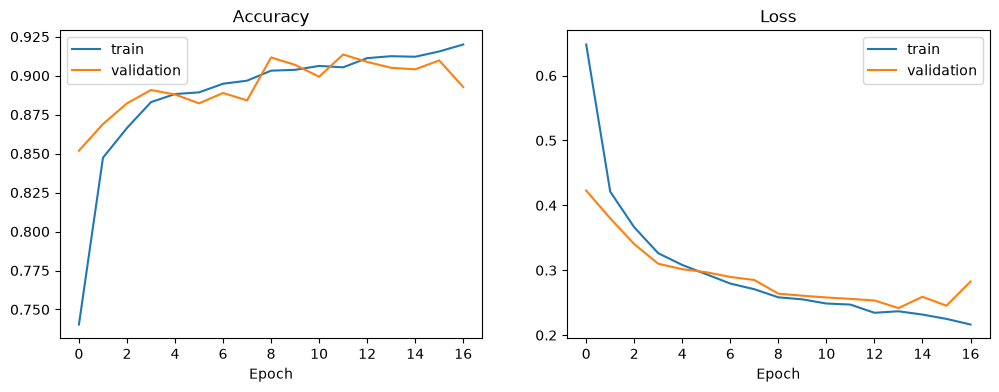

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.savefig("/app/reports/training_feature_extraction.png")
plt.show()

In [17]:
print("Epochs run:", len(history.history["val_loss"]))
print("Best val_loss:", min(history.history["val_loss"]))

Epochs run: 17
Best val_loss: 0.24173994362354279


In [18]:
import numpy as np

y_true = []
for images,labels in test_ds:
    y_true.extend(np.argmax(labels.numpy(),axis=1))
    
y_pred = np.argmax(model.predict(test_ds),axis=1)

2026-10-24 13:47:42.026076: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
I0000 00:00:1792849672.308304     736 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads



32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step

I0000 00:00:1792849677.537432    3398 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_2412', 244 bytes spill stores, 244 bytes spill loads



33/33 ━━━━━━━━━━━━━━━━━━━━ 30s 592ms/step


I0000 00:00:1792849691.532784     735 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads



In [19]:
from sklearn.metrics import classification_report
print(classification_report(y_true,y_pred,target_names=class_names))

              precision    recall  f1-score   support

      glioma       0.91      0.88      0.89       243
  meningioma       0.83      0.78      0.81       247
     notumor       0.96      0.98      0.97       300
   pituitary       0.90      0.96      0.93       264

    accuracy                           0.91      1054
   macro avg       0.90      0.90      0.90      1054
weighted avg       0.90      0.91      0.90      1054



In [20]:
train_loss, train_acc = model.evaluate(train_ds)
test_loss, test_acc = model.evaluate(test_ds)

print("train acc: ", train_acc)
print("test acc: ", test_acc)

175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 64ms/step - accuracy: 0.9457 - loss: 0.1618
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.9051 - loss: 0.2479

I0000 00:00:1792850064.201685     735 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads



33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 137ms/step - accuracy: 0.9051 - loss: 0.2479
train acc:  0.9457142949104309
test acc:  0.9051233530044556


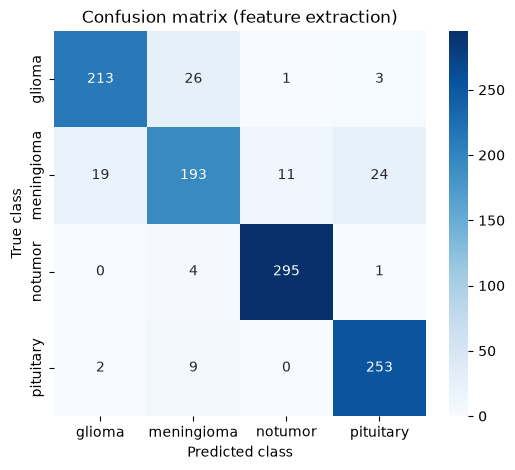

In [21]:
import seaborn as sns 
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true,y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix (feature extraction)")
plt.savefig("/app/reports/confusion_matrix_feature_extraction.png")
plt.show()

In [22]:
print(cm)

[[213  26   1   3]
 [ 19 193  11  24]
 [  0   4 295   1]
 [  2   9   0 253]]


In [26]:
print(len(base_model.layers))

311


In [14]:
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import json
import matplotlib.pyplot as plt

model = keras.models.load_model("/app/models/classification/best_feature_extraction.keras")
base_model = model.layers[0]
fe_test_acc = 0.9051

In [15]:
# fe_y_pred = y_pred

base_model.trainable = True

for layer in base_model.layers[:-50]:
    layer.trainable = False


for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
        
        
# trainable = [l for l in base_model.layers if l.trainable]
# print("Total layers in base:", len(base_model.layers))
# print("Trainable layers:", len(trainable))
model.summary()

Total layers in base: 311
Trainable layers: 35


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,827,374 (83.26 MB)

 Trainable params: 7,176,196 (27.38 MB)

 Non-trainable params: 14,634,784 (55.83 MB)

 Optimizer params: 16,394 (64.04 KB)

In [16]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="categorical_crossentropy",
    metrics=["accuracy"])

In [17]:
early_stop_ft = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True)

checkpoint_ft = ModelCheckpoint(
    "/app/models/classification/best_fine_tuning_last50.keras",
    monitor="val_loss",
    save_best_only=True)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop_ft, checkpoint_ft])

json.dump(history_ft.history, open("/app/reports/history_ft_last50.json", "w"))

Epoch 1/20


/usr/local/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793010195.025118     160 service.cc:145] XLA service 0x590de48a8960 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793010195.025342     160 service.cc:153]   StreamExecutor device (0): NVIDIA RTX 2000 Ada Generation Laptop GPU, Compute Capability 8.9
2026-10-26 10:23:15.386929: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-26 10:23:17.833677: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907
I0000 00:00:1793010221.806105     160 device_compiler

175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.9202 - loss: 0.2050

I0000 00:00:1793010245.068576     533 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_2455', 180 bytes spill stores, 180 bytes spill loads

I0000 00:00:1793010246.725025     158 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1793010252.603751     585 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_2455', 244 bytes spill stores, 244 bytes spill loads



175/175 ━━━━━━━━━━━━━━━━━━━━ 86s 289ms/step - accuracy: 0.9202 - loss: 0.2050 - val_accuracy: 0.9250 - val_loss: 0.1963
Epoch 2/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 28s 158ms/step - accuracy: 0.9539 - loss: 0.1326 - val_accuracy: 0.9354 - val_loss: 0.1632
Epoch 3/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 25s 142ms/step - accuracy: 0.9688 - loss: 0.0970 - val_accuracy: 0.9468 - val_loss: 0.1418
Epoch 4/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 26s 147ms/step - accuracy: 0.9811 - loss: 0.0611 - val_accuracy: 0.9487 - val_loss: 0.1355
Epoch 5/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 28s 161ms/step - accuracy: 0.9877 - loss: 0.0447 - val_accuracy: 0.9516 - val_loss: 0.1297
Epoch 6/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 26s 148ms/step - accuracy: 0.9904 - loss: 0.0322 - val_accuracy: 0.9601 - val_loss: 0.1122
Epoch 7/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 23s 132ms/step - accuracy: 0.9941 - loss: 0.0233 - val_accuracy: 0.9563 - val_loss: 0.1234
Epoch 8/20
175/175 ━━━━━━━━━━━━━━━━━━━━ 26s 148ms/step - accuracy: 0.9943 - loss: 0.0226 - val

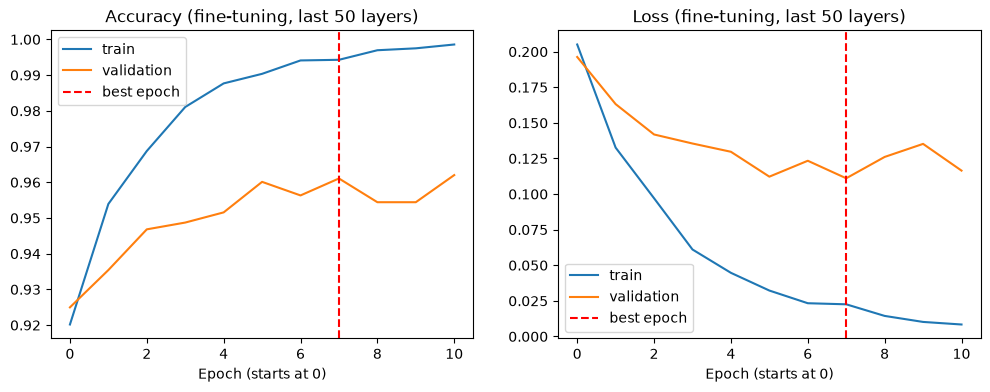

In [18]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_ft.history["accuracy"], label="train")
plt.plot(history_ft.history["val_accuracy"], label="validation")
plt.axvline(7, color="red", linestyle="--", label="best epoch")
plt.title("Accuracy (fine-tuning, last 50 layers)")
plt.xlabel("Epoch (starts at 0)")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_ft.history["loss"], label="train")
plt.plot(history_ft.history["val_loss"], label="validation")
plt.axvline(7, color="red", linestyle="--", label="best epoch")
plt.title("Loss (fine-tuning, last 50 layers)")
plt.xlabel("Epoch (starts at 0)")
plt.legend()

plt.savefig("/app/reports/training_fine_tuning_last50.png")
plt.show()

In [20]:
from sklearn.metrics import classification_report ,confusion_matrix
import seaborn as sns 
y_pred_ft = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred_ft, target_names=class_names))

train_loss, train_acc_ft = model.evaluate(train_ds)
test_loss, test_acc_ft = model.evaluate(test_ds)
print("Train accuracy:", train_acc_ft)
print("Test accuracy:", test_acc_ft)

I0000 00:00:1793012244.473686     156 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads



32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step

I0000 00:00:1793012249.421040    1704 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_2412', 244 bytes spill stores, 244 bytes spill loads



33/33 ━━━━━━━━━━━━━━━━━━━━ 21s 555ms/step


I0000 00:00:1793012262.634039     158 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads



              precision    recall  f1-score   support

      glioma       0.97      0.94      0.95       243
  meningioma       0.91      0.90      0.91       247
     notumor       0.99      0.98      0.99       300
   pituitary       0.94      0.98      0.96       264

    accuracy                           0.95      1054
   macro avg       0.95      0.95      0.95      1054
weighted avg       0.95      0.95      0.95      1054

175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.9993 - loss: 0.0070
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 125ms/step - accuracy: 0.9545 - loss: 0.1507
Train accuracy: 0.9992856979370117
Test accuracy: 0.9544591903686523


I0000 00:00:1793012278.968608     157 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads



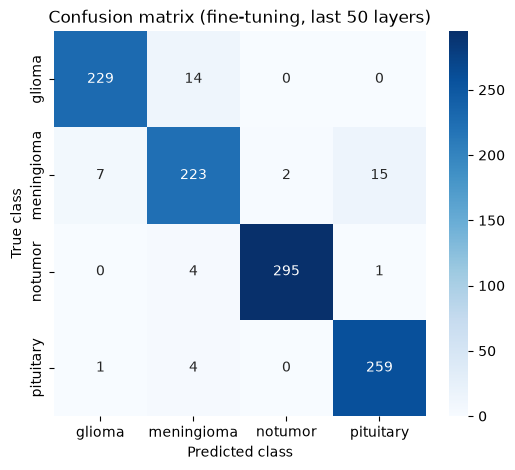

[[229  14   0   0]
 [  7 223   2  15]
 [  0   4 295   1]
 [  1   4   0 259]]


In [21]:
cm_ft = confusion_matrix(y_true, y_pred_ft)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_ft, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix (fine-tuning, last 50 layers)")
plt.savefig("/app/reports/confusion_matrix_fine_tuning_last50.png")
plt.show()

print(cm_ft)

In [22]:
print("Feature extraction test accuracy:      ", fe_test_acc)
print("Fine-tuning (last 50 layers) accuracy: ", test_acc_ft)
print("Fine-tuning (first run, 182 layers):    0.9630")

Feature extraction test accuracy:       0.9051
Fine-tuning (last 50 layers) accuracy:  0.9544591903686523
Fine-tuning (first run, 182 layers):    0.9630


In [3]:
final_model = keras.models.load_model("/app/models/classification/best_fine_tuning.keras")
loss, acc = final_model.evaluate(test_ds)
print("Test accuracy:", acc)

I0000 00:00:1793102832.510020     142 service.cc:145] XLA service 0x73f5b4002ec0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793102832.510067     142 service.cc:153]   StreamExecutor device (0): NVIDIA RTX 2000 Ada Generation Laptop GPU, Compute Capability 8.9
2026-10-27 12:07:12.781963: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-27 12:07:13.809475: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907
I0000 00:00:1793102834.423683     231 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_2455', 180 bytes spill stores, 180 bytes spill loads



 3/33 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.9896 - loss: 0.0289 

I0000 00:00:1793102849.240971     142 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1793102849.247092     142 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


32/33 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9619 - loss: 0.1211

I0000 00:00:1793102852.389774     303 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'triton_gemm_dot_2455', 244 bytes spill stores, 244 bytes spill loads



33/33 ━━━━━━━━━━━━━━━━━━━━ 37s 535ms/step - accuracy: 0.9630 - loss: 0.1176
Test accuracy: 0.96299809217453


I0000 00:00:1793102866.347246     144 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_concatenate_multiply_fusion', 8 bytes spill stores, 8 bytes spill loads



In [4]:
final_model.save("/app/models/classification/inceptionv3_final.keras")
json.dump(class_names, open("/app/models/classification/class_names.json", "w"))
print("Saved")

Saved
